In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
BASE_DIR = Path.cwd()
data_path_1 = Path.cwd() / "data" / "ECG_Data" / "ECG_Resting.txt"
data_path_2 = Path.cwd() / "data" / "ECG_Data" / "ECG_Deep_Breathing.txt"
data_path_3 = Path.cwd() / "data" / "ECG_Data" / "ECG_Post_Exercise.txt"

signal_rest = np.loadtxt(data_path_1)
signal_deep_breath = np.loadtxt(data_path_2)
signal_post_exercise = np.loadtxt(data_path_3)

In [3]:
sampling_rate = 1000 #Hz
print("Duration of recordings:")
print(f"resting state : {len(signal_rest)/sampling_rate} seconds")
print(f"deep breathing : {len(signal_deep_breath)/sampling_rate} seconds")
print(f"post exercise : {len(signal_post_exercise)/sampling_rate} seconds")

Duration of recordings:
resting state : 60.127 seconds
deep breathing : 50.421 seconds
post exercise : 72.464 seconds


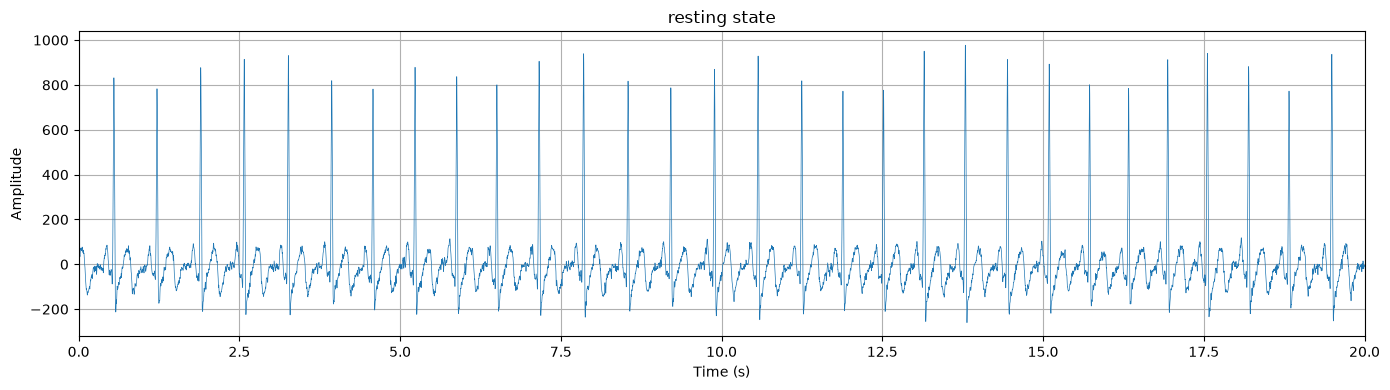

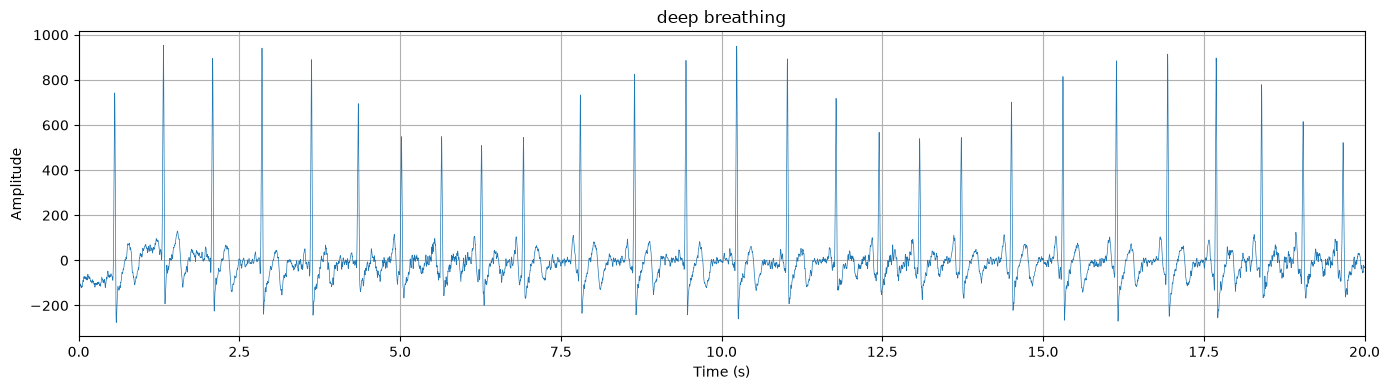

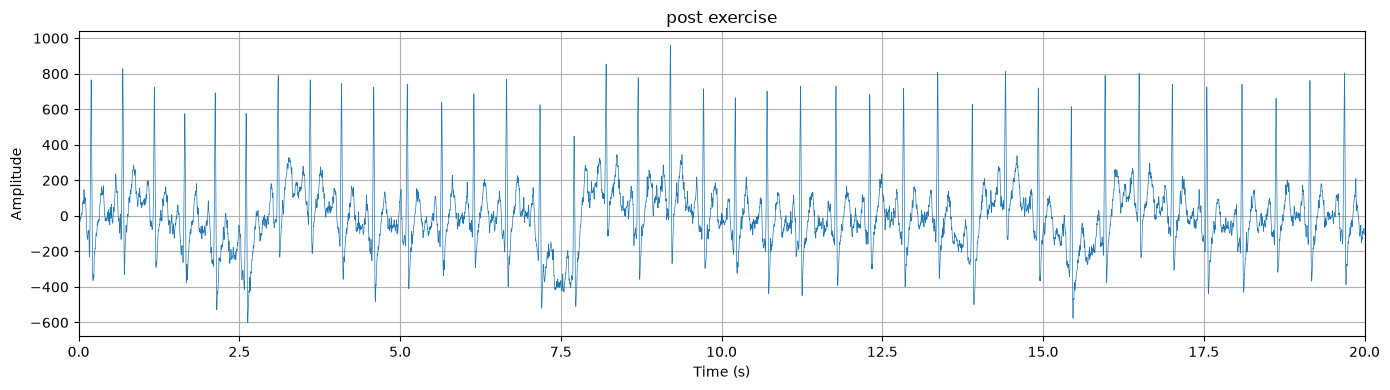

In [4]:
def plot_segment(signal, title, start_time, end_time, sampling_rate = 1000):
    start_sample = int(start_time * sampling_rate)
    end_sample = int(end_time * sampling_rate)
    segment = signal[start_sample : end_sample]
    time = np.arange(len(segment))/sampling_rate

    plt.figure(figsize=(14, 4))

    plt.plot(time, segment, linewidth=0.5)

    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title(title)
    plt.grid(True)
    plt.xlim(0, len(segment) / sampling_rate)

    plt.tight_layout()
    plt.show()

plot_segment(signal_rest, "resting state", 10, 30, sampling_rate = 1000)
plot_segment(signal_deep_breath, "deep breathing", 10, 30, sampling_rate = 1000)
plot_segment(signal_post_exercise, "post exercise", 10, 30, sampling_rate = 1000)

In [7]:
from scipy import signal

class pan_tompkins:
    def __init__(self, ECG, Fs, window_ms):
        self.ECG = ECG
        self.Fs = Fs
        self.window_ms = window_ms

    def BandPass(self):
    
        W1 = 5*2/self.Fs                                   
        W2 = 15*2/self.Fs                                 
        b, a = signal.butter(4, [W1,W2], 'bandpass') # defining parameters    
        ECG_BP = signal.filtfilt(b,a,np.transpose(self.ECG)) # implemening filter   
        return ECG_BP

    def Differentiate(self, ECG_BP):
        
        ECG_df  = np.diff(ECG_BP)
        ECG_sq  = np.power(ECG_df,2)
        return np.insert(ECG_sq,0, ECG_sq[0]) # to maintain the size of the array

    def MovingAverage(self, ECG_sq):
        
        N = max(1, int(round(self.Fs * self.window_ms / 1000)))
        window  = np.ones((N))/N
        ECG_ma  = np.convolve(np.squeeze(ECG_sq),np.squeeze(window))
        return ECG_ma

    def QRSpeaks(self, ECG_ma):
        # Estimated average heart rate in BPM
        peaks, _  = signal.find_peaks(ECG_ma, height=np.mean(ECG_ma), distance=round(self.Fs*0.200))
        num_beats = len(peaks)
        RR_intervals = np.diff(peaks) / self.Fs
        heart_rate = 60 / np.mean(RR_intervals) 

        print(f"The total number of peaks detected over the entire duration: {num_beats}")  
        print(f"The estimated average heart rate in BPM: {heart_rate}") 
        

    def PlotSegment(self, processed_signal, title, start_time, end_time):

        start_sample = int(start_time * self.Fs)
        end_sample = int(end_time * self.Fs)

        original_segment = self.ECG[start_sample:end_sample]
        processed_segment = processed_signal[start_sample:end_sample]

        time = np.arange(len(original_segment)) / self.Fs

        plt.figure(figsize=(14, 4))

        plt.plot(time, original_segment,
                 color="blue", linewidth=0.5, label="Original ECG")

        plt.plot(time, processed_segment,
                 color="red", linewidth=0.8, label="Processed ECG")

        plt.xlabel("Time (s)")
        plt.ylabel("Amplitude")
        plt.title(title)
        plt.grid(True)
        plt.legend()
        plt.xlim(0, len(original_segment) / self.Fs)

        plt.tight_layout()
        plt.show()

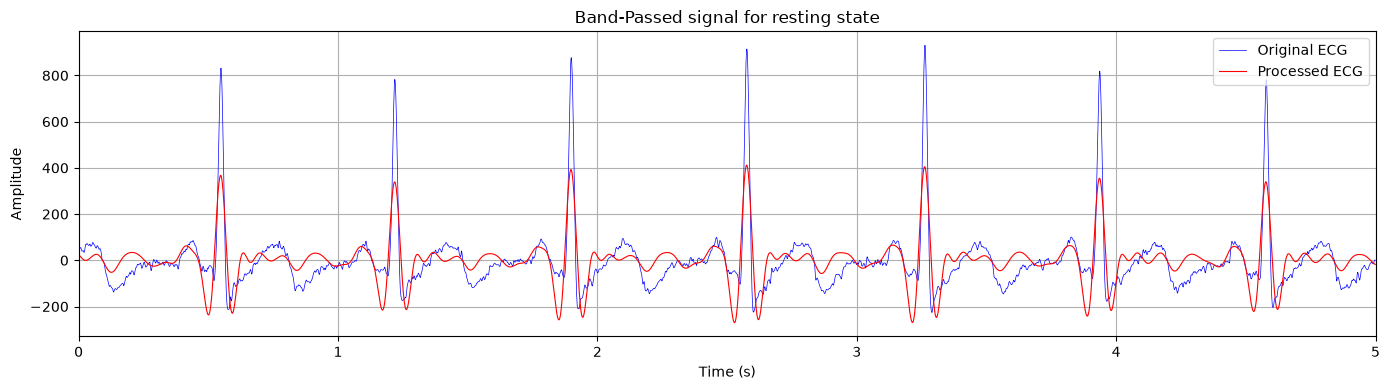

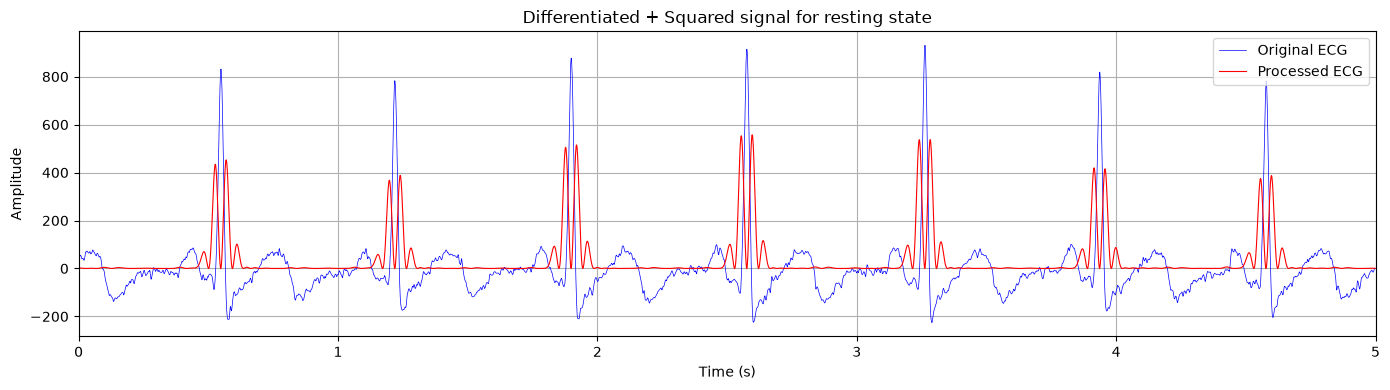

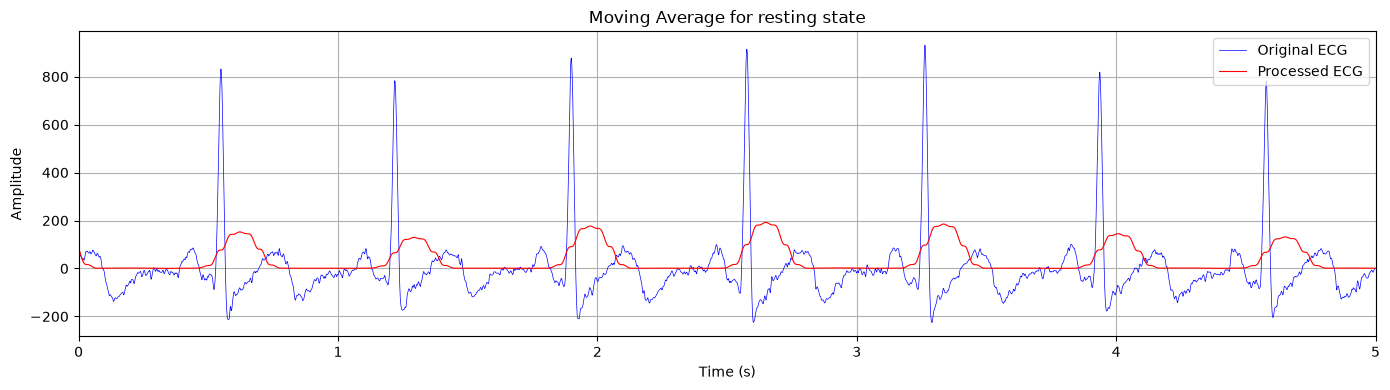

The total number of peaks detected over the entire duration: 91
The estimated average heart rate in BPM: 90.57363300905736


In [8]:
resting_state = pan_tompkins(signal_rest, 1000, 150)
resting_state_BP = resting_state.BandPass()
resting_state.PlotSegment(resting_state_BP,"Band-Passed signal for resting state", 10, 15)

resting_state_DF = resting_state.Differentiate(resting_state_BP)
resting_state.PlotSegment(resting_state_DF,"Differentiated + Squared signal for resting state", 10, 15)

resting_state_MA = resting_state.MovingAverage(resting_state_DF)
resting_state.PlotSegment(resting_state_MA,"Moving Average for resting state", 10, 15)

resting_state.QRSpeaks(resting_state_MA)

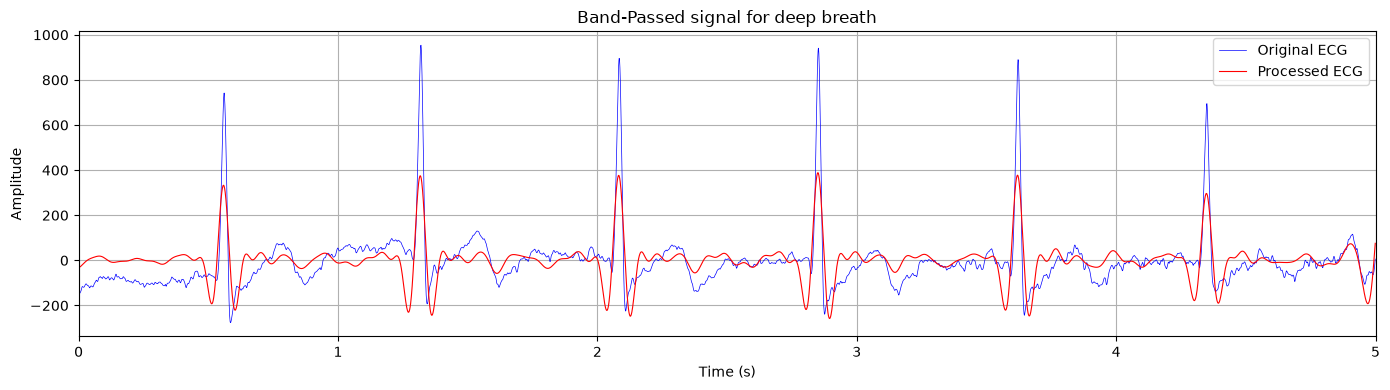

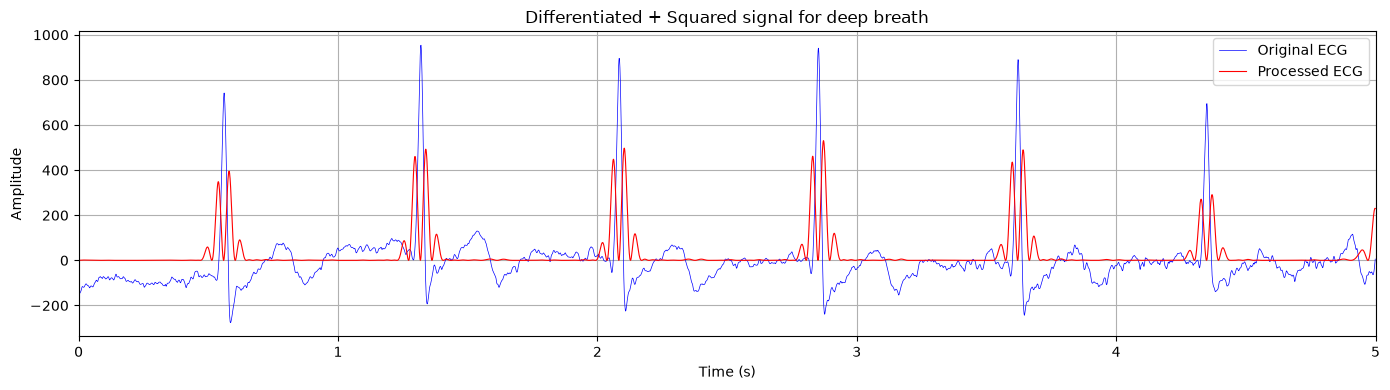

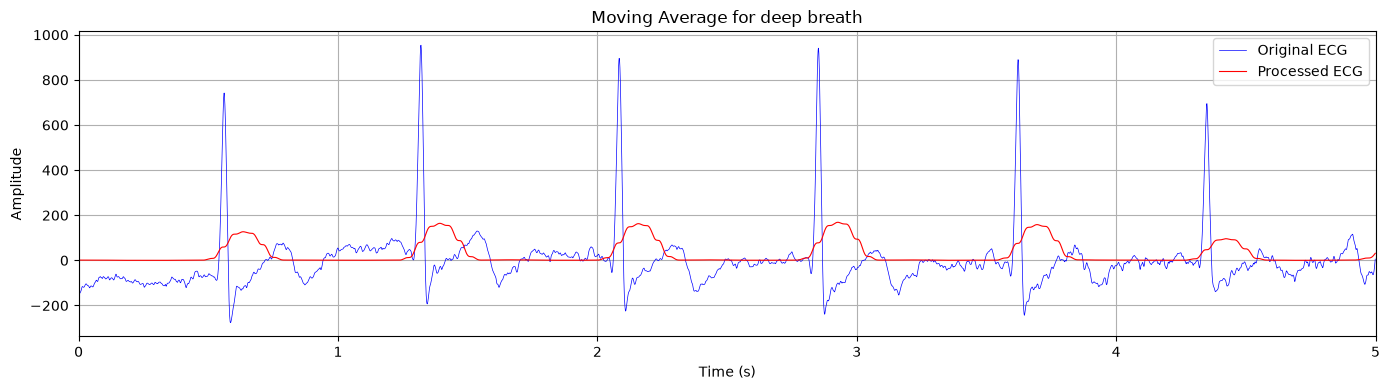

The total number of peaks detected over the entire duration: 73
The estimated average heart rate in BPM: 86.74872989417459


In [9]:
deep_breath = pan_tompkins(signal_deep_breath, 1000, 150)
deep_breath_BP = deep_breath.BandPass()
deep_breath.PlotSegment(deep_breath_BP,"Band-Passed signal for deep breath", 10, 15)

deep_breath_DF = deep_breath.Differentiate(deep_breath_BP)
deep_breath.PlotSegment(deep_breath_DF,"Differentiated + Squared signal for deep breath", 10, 15)

deep_breath_MA = deep_breath.MovingAverage(deep_breath_DF)
deep_breath.PlotSegment(deep_breath_MA,"Moving Average for deep breath", 10, 15)

deep_breath.QRSpeaks(deep_breath_MA)

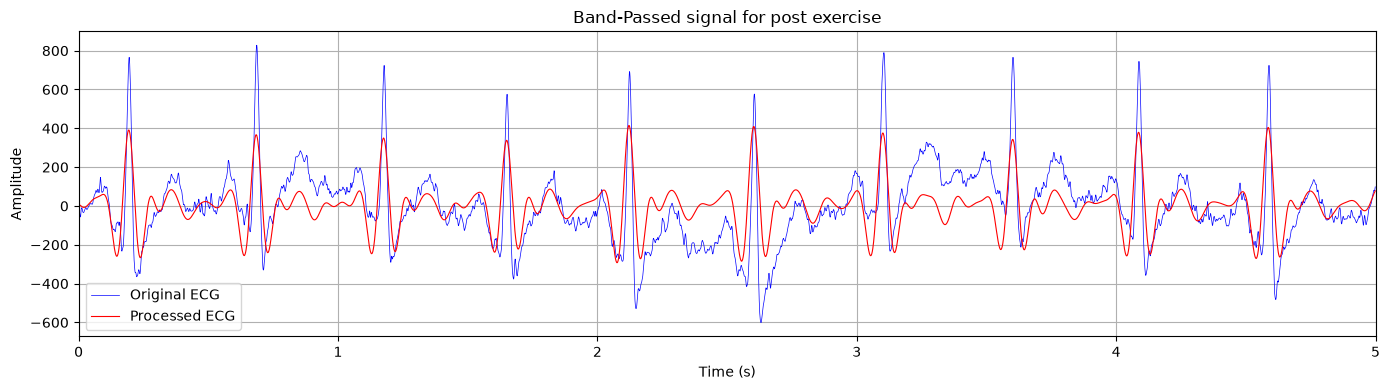

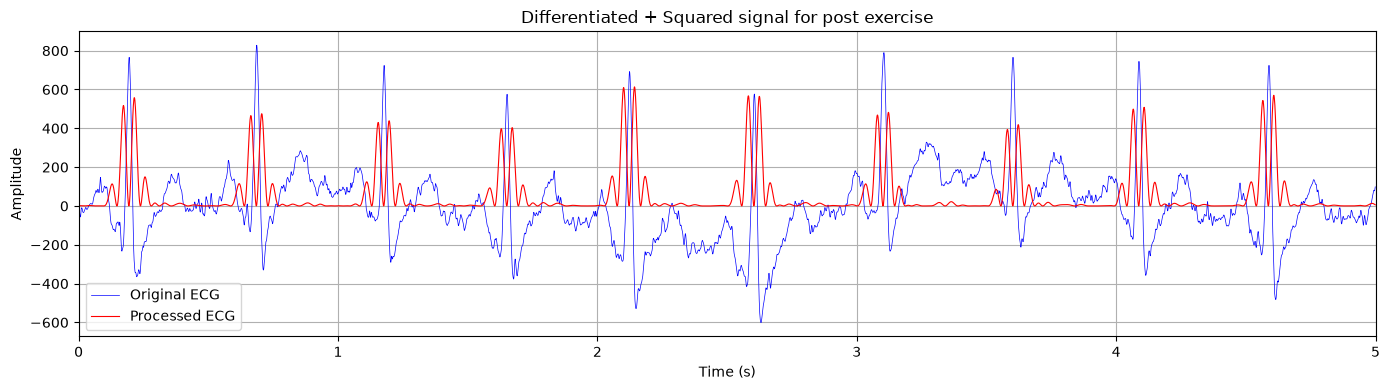

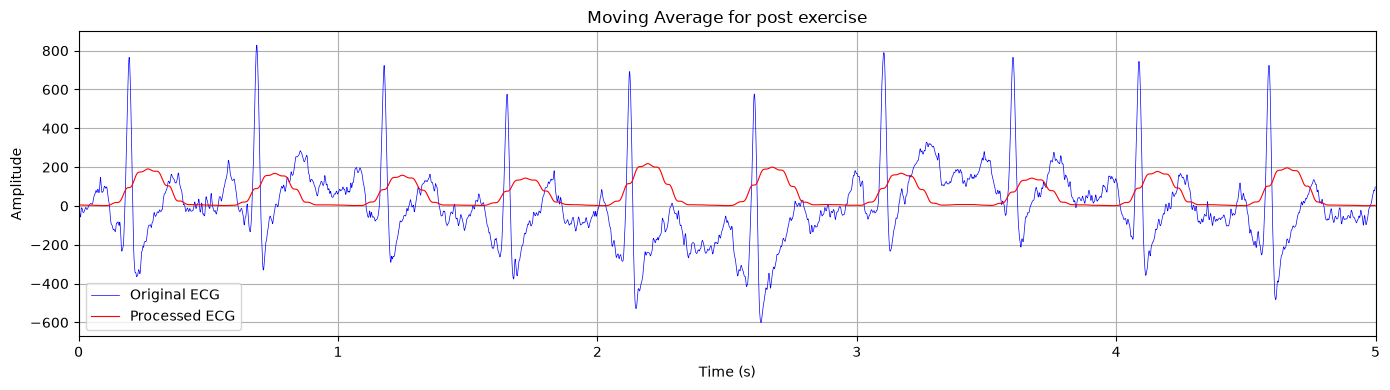

The total number of peaks detected over the entire duration: 138
The estimated average heart rate in BPM: 114.36203514336991


In [10]:
post_exercise = pan_tompkins(signal_post_exercise, 1000, 150)
post_exercise_BP = post_exercise.BandPass()
post_exercise.PlotSegment(post_exercise_BP,"Band-Passed signal for post exercise", 10, 15)

post_exercise_DF = post_exercise.Differentiate(post_exercise_BP)
post_exercise.PlotSegment(post_exercise_DF,"Differentiated + Squared signal for post exercise", 10, 15)

post_exercise_MA = post_exercise.MovingAverage(post_exercise_DF)
post_exercise.PlotSegment(post_exercise_MA,"Moving Average for post exercise", 10, 15)

post_exercise.QRSpeaks(post_exercise_MA)